# 02 · Regional edits

Notebook 01 moved the whole square along one trajectory `exp(-t·v)`. Here each region gets its own time:
`φ = exp(-w(x)·v)` with a weight map `w(x)`. Because the weight multiplies the *velocity*, the result is
still a single smooth, invertible map, and image and labels are warped together.

There are two ways to attach `w` to the image:

- **Eulerian**: `w` is fixed in space (`exp(v, w)`, fast scaling and squaring). Tissue that flows out of a
  region stops partway.
- **Lagrangian**: `w` is attached to the tissue it was built from (`integrate(v, w)`, the default for
  regional augmentation). Each structure moves by its own `t` all the way.

Requires the `io` and `viz` extras and NiftyReg on `PATH` (or `NIFTYREG_BIN` set).

In [ ]:
import os
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from drift import weights
from drift.filters import gaussian_smooth
from drift.flow import exp, integrate
from drift.grid import identity, warp, warp_labels
from drift.io import save_nifti
from drift.jacobian import det
from drift.registration.niftyreg import NiftyReg, NiftyRegParams
from drift.space import ImageSpace

local = Path("..") / "third_party" / "niftyreg" / "install" / "bin"
if "NIFTYREG_BIN" not in os.environ and local.is_dir():
    os.environ["NIFTYREG_BIN"] = str(local.resolve())

## The square → circle field from notebook 01

In [ ]:
n = 64
x = identity((n, n)) - (n - 1) / 2
square = gaussian_smooth((x.abs().amax(1, keepdim=True) <= 13.5).float(), 1.5)
circle = gaussian_smooth((x.norm(dim=1, keepdim=True) <= 15.5).float(), 1.5)
space = ImageSpace.from_spacing((n, n), spacing=1.5)

tmp = Path(tempfile.mkdtemp())
save_nifti(tmp / "square.nii.gz", square, space)
save_nifti(tmp / "circle.nii.gz", circle, space)
params = NiftyRegParams(
    cp_spacing=-4.0, similarity="ssd", bending_energy=0.0005, linear_elasticity=0.0
)
v = NiftyReg(params).register(tmp / "square.nii.gz", tmp / "circle.nii.gz").velocity
v_aug = -v  # augmentation samples A ∘ exp(-t·v)
print(f"max |v| = {float(v.norm(dim=1).max()):.2f} voxels")

max |v| = 3.27 voxels


## Times from labels

Split the square into a left half (label 1) and a right half (label 2), and give them different times:
the left half goes *past* the circle (`t = 2.5`) and the right half goes the other way (`t = -1`), with the
background at `t = 0`. No single `t` on the square → circle path produces this shape.

`weights.from_labels` paints the times and smooths them. `sigma` is in voxels; `weights.sigma_voxels`
converts from mm for real images.

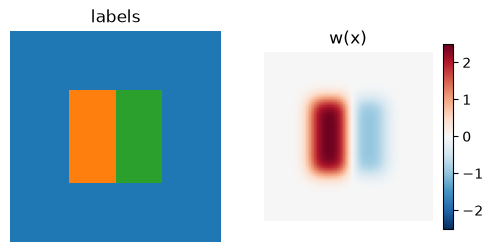

In [ ]:
inside = (x.abs().amax(1, keepdim=True) <= 13.5).long()
labels = inside * torch.where(x[:, 1:2] < 0, 1, 2)
times = {1: 2.5, 2: -1.0}
w = weights.from_labels(labels, times, t_bg=0.0, sigma=weights.sigma_voxels(4.5, space))

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(labels[0, 0], cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
ax[0].set_title("labels")
im = ax[1].imshow(w[0, 0], cmap="RdBu_r", vmin=-2.5, vmax=2.5)
ax[1].set_title("w(x)")
fig.colorbar(im, ax=ax[1], shrink=0.8)
for a in ax:
    a.axis("off")

## Keep `w` smooth enough

The Lagrangian map is only invertible while `|∇w · v| < 1`: otherwise a fast region runs into a slow
one and the tissue collides (det J ≤ 0). `weights.rate` measures this and `weights.limit_rate` smooths `w`
further (and, as a last resort, pulls the times together) until it is below a bound, 0.5 by default.

In [ ]:
sharp = weights.from_labels(labels, times)
print(f"rate, unsmoothed: {float(weights.rate(sharp, v_aug)):.2f}")
print(f"rate, sigma 3 voxels: {float(weights.rate(w, v_aug)):.2f}")
print(f"det J min, unsmoothed Lagrangian: {float(det(integrate(v_aug, sharp)).min()):.2f}")
w = weights.limit_rate(w, v_aug)
print(f"rate after limit_rate: {float(weights.rate(w, v_aug)):.2f}")

rate, unsmoothed: 4.63
rate, sigma 3 voxels: 0.76
det J min, unsmoothed Lagrangian: -1.85
rate after limit_rate: 0.47


## Eulerian vs Lagrangian

Columns: the global trajectory at `t = 2.5` and `t = -1` for reference, then the regional edit in both
modes; the middle row shows the warped labels and the bottom row det J. The left half rounds out past the
circle while the right half barely moves, and det J stays positive everywhere.

The two modes differ only where `w` changes, by how far tissue travels across the transition zone during
the flow. Here that is about a voxel, because `limit_rate` keeps `|∇w · v|` small. The difference
grows with the displacement relative to the width of the transition, i.e. for large `t` on real
inter-patient fields; Lagrangian mode is the one that keeps each structure's time attached to it.

max |Lagrangian - Eulerian| = 1.02 voxels


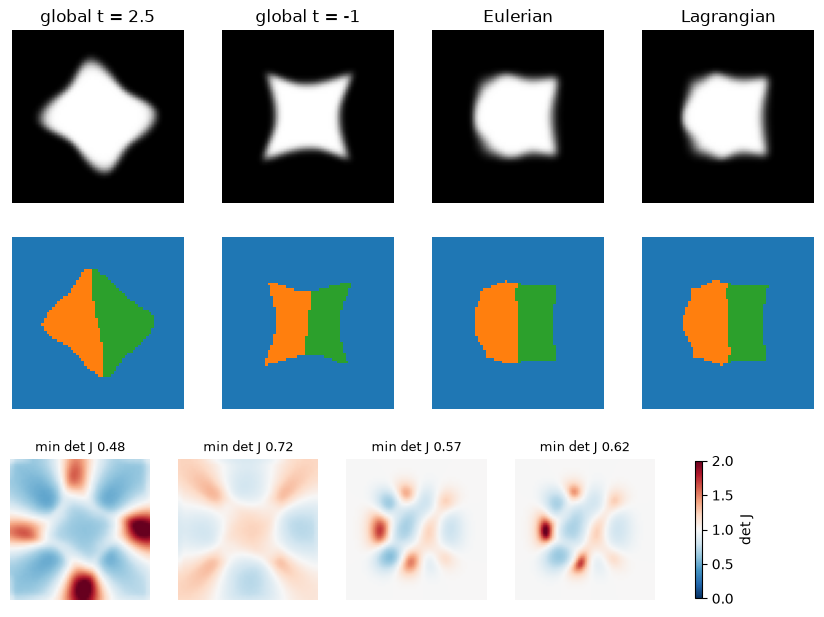

In [ ]:
maps = {
    "global t = 2.5": exp(v_aug, 2.5),
    "global t = -1": exp(v_aug, -1.0),
    "Eulerian": exp(v_aug, w),
    "Lagrangian": integrate(v_aug, w),
}
fig, ax = plt.subplots(3, len(maps), figsize=(2.6 * len(maps), 7.6))
for i, (title, phi) in enumerate(maps.items()):
    ax[0, i].imshow(warp(square, phi)[0, 0], cmap="gray", vmin=0, vmax=1)
    ax[0, i].set_title(title)
    ax[1, i].imshow(
        warp_labels(labels, phi)[0, 0], cmap="tab10", vmin=0, vmax=9, interpolation="nearest"
    )
    dj = det(phi)[0]
    im = ax[2, i].imshow(dj, cmap="RdBu_r", vmin=0, vmax=2)
    ax[2, i].set_title(f"min det J {float(dj.min()):.2f}", fontsize=9)
    for a in ax[:, i]:
        a.axis("off")
fig.colorbar(im, ax=ax[2], shrink=0.8, label="det J")
diff = (maps["Lagrangian"] - maps["Eulerian"]).norm(dim=1).max()
print(f"max |Lagrangian - Eulerian| = {float(diff):.2f} voxels")

## Random regions

`weights.random_blobs` scatters Gaussian blobs with random times, here centred inside the square. Each
sample is a different, fold-free shape built from the same registration.

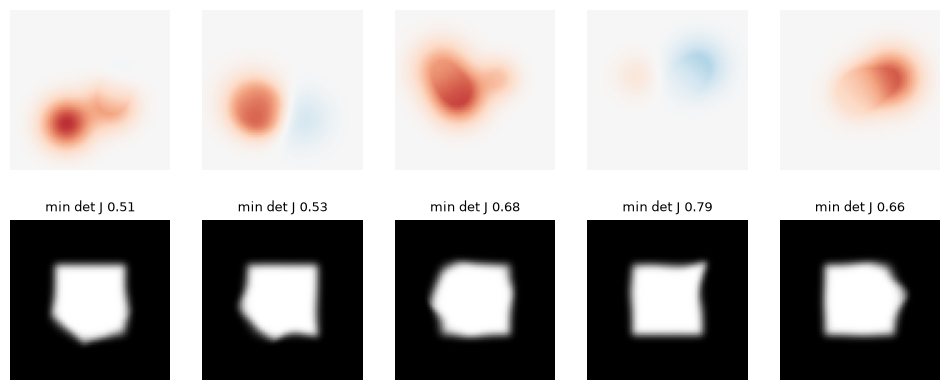

In [ ]:
g = torch.Generator().manual_seed(0)
blobs = weights.random_blobs(
    (n, n), 3, t=(-1.0, 2.5), sigma=(5.0, 9.0), t_bg=0.0, within=inside, batch=5, generator=g
)
blobs = weights.limit_rate(blobs, v_aug)
phi = integrate(v_aug.expand(5, -1, -1, -1), blobs)
out = warp(square.expand(5, -1, -1, -1), phi)
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    ax[0, i].imshow(blobs[i, 0], cmap="RdBu_r", vmin=-2.5, vmax=2.5)
    ax[1, i].imshow(out[i, 0], cmap="gray", vmin=0, vmax=1)
    ax[1, i].set_title(f"min det J {float(det(phi[i : i + 1]).min()):.2f}", fontsize=9)
    for a in ax[:, i]:
        a.axis("off")